In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame.copy()
print("Dataset Shape:", df.shape)
print("Features:", list(diabetes.feature_names))
print("Missing values:", df.isnull().sum().sum())
display(df.head())
display(df.describe().T[['mean', 'std', 'min', 'max']])

Dataset Shape: (442, 11)
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Missing values: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


,mean,std,min,max
age,-2.511817e-19,0.047619,-0.107226,0.110727
sex,1.230790e-17,0.047619,-0.044642,0.050680
bmi,-2.245564e-16,0.047619,-0.090275,0.170555
bp,-4.797570e-17,0.047619,-0.112399,0.132044
s1,-1.381499e-17,0.047619,-0.126781,0.153914
s2,3.918434e-17,0.047619,-0.115613,0.198788
s3,-5.777179e-18,0.047619,-0.102307,0.181179
s4,-9.042540e-18,0.047619,-0.076395,0.185234
s5,9.268604e-17,0.047619,-0.126097,0.133597
s6,1.130318e-17,0.047619,-0.137767,0.135612


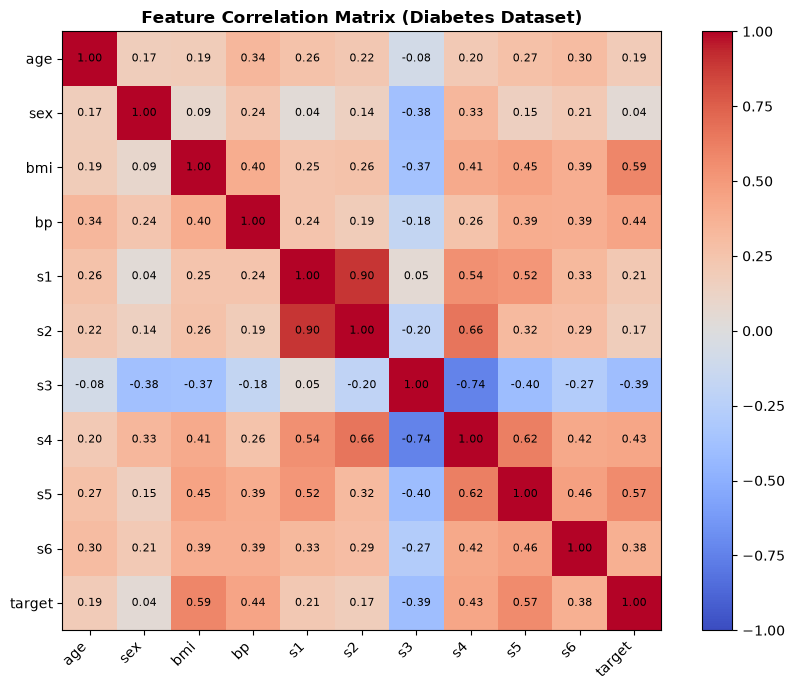

In [3]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax, fraction=0.046)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticklabels(corr.columns)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha='center', va='center', color='black', fontsize=8)
ax.set_title('Feature Correlation Matrix (Diabetes Dataset)', fontweight='bold')
plt.tight_layout()
plt.show()

In [4]:
X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled, y_train)

coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': np.round(model.coef_, 3)
}).sort_values(by='Coefficient', key=abs, ascending=False)

print(f"Intercept (beta_0): {model.intercept_:.3f}")
display(coef_df)

Intercept (beta_0): 153.737


,Feature,Coefficient
4,s1,-44.449
8,s5,35.161
2,bmi,25.607
5,s2,24.641
3,bp,16.829
7,s4,13.139
1,sex,-11.512
6,s3,7.677
9,s6,2.351
0,age,1.754


MAE         : 42.794
RMSE        : 53.853
R2 Score    : 0.4526
Adjusted R2 : 0.3824


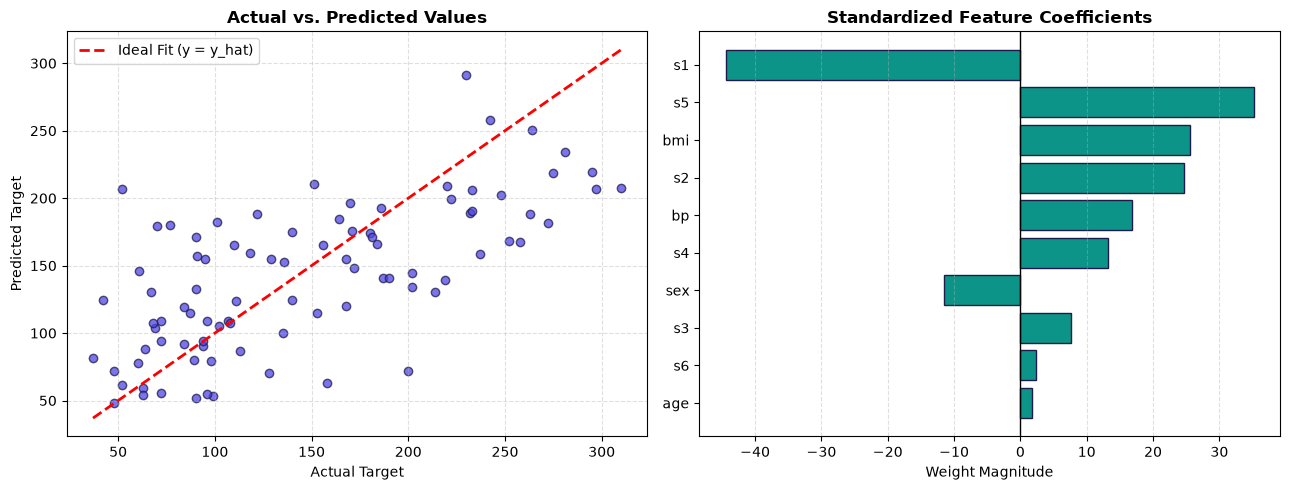

In [5]:
y_pred = model.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
n, p = X_test.shape
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print(f"MAE         : {mae:.3f}")
print(f"RMSE        : {rmse:.3f}")
print(f"R2 Score    : {r2:.4f}")
print(f"Adjusted R2 : {adj_r2:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.scatter(y_test, y_pred, color='#4F46E5', alpha=0.75, edgecolor='#1E1B4B')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax1.plot(lims, lims, 'r--', lw=2, label='Ideal Fit (y = y_hat)')
ax1.set_title('Actual vs. Predicted Values', fontweight='bold')
ax1.set_xlabel('Actual Target'); ax1.set_ylabel('Predicted Target')
ax1.legend(); ax1.grid(True, linestyle='--', alpha=0.4)

ax2.barh(coef_df['Feature'][::-1], coef_df['Coefficient'][::-1], color='#0D9488', edgecolor='#1E1B4B')
ax2.axvline(0, color='black', lw=1)
ax2.set_title('Standardized Feature Coefficients', fontweight='bold')
ax2.set_xlabel('Weight Magnitude')
ax2.grid(True, axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()